#**Deep Learning - Lab 6 - Raja Rayyan Ameer - 23-CP-25**

In [41]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import rotate, shift
from sklearn.datasets import load_digits
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, precision_recall_curve
from IPython.display import display
import pandas as pd

In [42]:
# Reproducible experiment settings from the lab manual
np.random.seed(42)
DEV_A = dict(ang=9.0, sh=0.7, noise=0.16)
DEV_B = dict(ang=14.0, sh=1.0, noise=0.24)
COPIES = 10
EPOCHS = 25
BATCH_SIZE = 64
LEARNING_RATE = 0.01

def degrade(images, seed=0, ang=9.0, sh=0.7, noise=0.16):
    """Simulate a scanner by rotating, shifting and adding noise to 8x8 images."""
    rng = np.random.RandomState(seed)
    out = np.empty_like(images, dtype=np.float32)
    for i, image in enumerate(images):
        image = rotate(image, rng.uniform(-ang, ang), reshape=False,
                       order=1, mode="constant", cval=0.0)
        image = shift(image, (rng.uniform(-sh, sh), rng.uniform(-sh, sh)),
                      order=1, mode="constant", cval=0.0)
        out[i] = np.clip(image + rng.randn(*image.shape) * noise, 0, 1)
    return out

# Create device A and device B scans of the same source digits.
digits_data = load_digits()
BASE_IMG = digits_data.images.astype(np.float32) / 16.0
BASE_DIGIT = digits_data.target
IMG_A = np.concatenate([degrade(BASE_IMG, seed=200+k, **DEV_A) for k in range(COPIES)])
IMG_B = np.concatenate([degrade(BASE_IMG, seed=700+k, **DEV_B) for k in range(COPIES)])
DIGIT = np.tile(BASE_DIGIT, COPIES)
Yall = (DIGIT == 8).astype(np.float32)
permutation = np.random.RandomState(3).permutation(len(Yall))
IMG_A, IMG_B, DIGIT, Yall = IMG_A[permutation], IMG_B[permutation], DIGIT[permutation], Yall[permutation]

# Keep the notebook's feature matrices in (features, examples) format.
X_A = IMG_A.reshape(len(IMG_A), -1).T.astype(np.float32)
X_B = IMG_B.reshape(len(IMG_B), -1).T.astype(np.float32)
Y = Yall.reshape(1, -1).astype(np.float32)
DIGITS = DIGIT

# Exact split sizes requested in the manual.
i_train, i_train_dev, i_dev = 12000, 13200, 15000
X_train, Y_train = X_A[:, :i_train], Y[:, :i_train]
X_train_dev, Y_train_dev = X_A[:, i_train:i_train_dev], Y[:, i_train:i_train_dev]
X_dev, Y_dev = X_A[:, i_train_dev:i_dev], Y[:, i_train_dev:i_dev]
X_test, Y_test = X_A[:, i_dev:], Y[:, i_dev:]
X_dev_B, Y_dev_B = X_B[:, i_train_dev:i_dev], Y[:, i_train_dev:i_dev]
X_test_B, Y_test_B = X_B[:, i_dev:], Y[:, i_dev:]
DIGIT_dev = DIGITS[i_train_dev:i_dev]

def sigmoid(z):
    z = np.clip(z, -30, 30)
    return 1.0 / (1.0 + np.exp(-z))

def initialize_network(layer_sizes, seed=42):
    """Initialize a small neural network using He initialization."""
    rng = np.random.RandomState(seed)
    params = {}
    for layer in range(1, len(layer_sizes)):
        fan_in, fan_out = layer_sizes[layer-1], layer_sizes[layer]
        scale = np.sqrt(2.0 / fan_in) if layer < len(layer_sizes)-1 else np.sqrt(1.0 / fan_in)
        params["W"+str(layer)] = (rng.randn(fan_out, fan_in) * scale).astype(np.float32)
        params["b"+str(layer)] = np.zeros((fan_out, 1), dtype=np.float32)
    return params

def forward(X, params, layer_sizes):
    activations = [X]
    L = len(layer_sizes)-1
    for layer in range(1, L+1):
        z = params["W"+str(layer)] @ activations[-1] + params["b"+str(layer)]
        a = sigmoid(z) if layer == L else np.maximum(0, z)
        activations.append(a)
    return activations

def train_network(X, Y, layer_sizes=(64, 16, 1), epochs=25, batch_size=64,
                  learning_rate=0.01, seed=42):
    """Train the network with mini-batch gradient descent and Adam."""
    params = initialize_network(list(layer_sizes), seed)
    m = {k: np.zeros_like(v) for k, v in params.items()}
    v = {k: np.zeros_like(val) for k, val in params.items()}
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8
    step = 0
    rng = np.random.RandomState(seed)
    n = X.shape[1]
    for epoch in range(epochs):
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            idx = order[start:start+batch_size]
            xb, yb = X[:, idx], Y[:, idx]
            acts = forward(xb, params, layer_sizes)
            grads = {}
            # Sigmoid output + binary cross-entropy gives this simple output gradient.
            delta = acts[-1] - yb
            for layer in range(len(layer_sizes)-1, 0, -1):
                grads["W"+str(layer)] = (delta @ acts[layer-1].T) / len(idx)
                grads["b"+str(layer)] = np.mean(delta, axis=1, keepdims=True)
                if layer > 1:
                    delta = (params["W"+str(layer)].T @ delta) * (acts[layer-1] > 0)
            step += 1
            for key in params:
                m[key] = beta1*m[key] + (1-beta1)*grads[key]
                v[key] = beta2*v[key] + (1-beta2)*(grads[key]**2)
                m_hat = m[key] / (1-beta1**step)
                v_hat = v[key] / (1-beta2**step)
                params[key] -= learning_rate*m_hat/(np.sqrt(v_hat)+epsilon)
    return params

def predict_prob(X, params, layer_sizes):
    return forward(X, params, layer_sizes)[-1].ravel()

def metrics_at_threshold(y_true, probabilities, threshold=0.5):
    y_true = np.asarray(y_true).ravel().astype(int)
    y_pred = (np.asarray(probabilities).ravel() >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "predictions": y_pred
    }

def error_percent(y_true, probabilities, threshold=0.5):
    return 100 * np.mean((np.asarray(probabilities).ravel() >= threshold) != np.asarray(y_true).ravel())

print("Dataset ready")
print(f"Total examples: {len(Yall):,}; positive fraction: {Yall.mean():.3f}")
print(f"Train {X_train.shape[1]:,} | train-dev {X_train_dev.shape[1]:,} | dev {X_dev.shape[1]:,} | test {X_test.shape[1]:,}")

Dataset ready
Total examples: 17,970; positive fraction: 0.097
Train 12,000 | train-dev 1,200 | dev 1,800 | test 2,970


##**Task 1: Build the First System Quickly**

###**1. Split the data into four sets: training (first 12000), train-dev (next 1200), dev (next 1800) and test (the remainder), all from device A. Report the size and the positive fraction of each.**

In [43]:
sets = {
    "Training": Y_train,
    "Train-dev": Y_train_dev,
    "Dev": Y_dev,
    "Test": Y_test
}
split_table = pd.DataFrame([
    {"Set": name, "Examples": values.shape[1], "Positive fraction": float(values.mean())}
    for name, values in sets.items()
])
display(split_table)

,Set,Examples,Positive fraction
0,Training,12000,0.096833
1,Train-dev,1200,0.092500
2,Dev,1800,0.092222
3,Test,2970,0.101347


###**2. Train the baseline architecture and report training accuracy, dev accuracy, and the wall-clock time taken to build it. You should be finished within a minute of starting.**

In [44]:
start_time = time.time()
baseline = train_network(X_train, Y_train, layer_sizes=(64, 16, 1),
                         epochs=EPOCHS, batch_size=BATCH_SIZE,
                         learning_rate=LEARNING_RATE, seed=42)
baseline_seconds = time.time() - start_time
p_train = predict_prob(X_train, baseline, (64, 16, 1))
p_dev = predict_prob(X_dev, baseline, (64, 16, 1))
print(f"Training accuracy: {metrics_at_threshold(Y_train, p_train)['accuracy']:.4f}")
print(f"Dev accuracy:      {metrics_at_threshold(Y_dev, p_dev)['accuracy']:.4f}")
print(f"Training time:     {baseline_seconds:.2f} seconds")

Training accuracy: 0.9603
Dev accuracy:      0.9472
Training time:     1.15 seconds


###**3. Compute the dev accuracy of the trivial classifier that always answers 'not an 8'. Report how many percentage points your trained network beats it by.**

In [45]:
always_negative = np.zeros(Y_dev.shape[1], dtype=int)
negative_accuracy = accuracy_score(Y_dev.ravel(), always_negative)
model_accuracy = metrics_at_threshold(Y_dev, p_dev)["accuracy"]
print(f"Always-negative dev accuracy: {negative_accuracy:.4f}")
print(f"Baseline dev accuracy:        {model_accuracy:.4f}")
print(f"Baseline improvement:         {(model_accuracy-negative_accuracy)*100:.2f} percentage points")

Always-negative dev accuracy: 0.9078
Baseline dev accuracy:        0.9472
Baseline improvement:         3.94 percentage points


###**4. State, in one or two sentences, why that comparison means the accuracy figure on its own is not usable as a progress measure for this project.**

In [46]:
print("Accuracy alone is misleading because only about 9.7% of examples are digit 8. "
      "A model can achieve high accuracy by predicting 'not an 8' for every image, "
      "while detecting no 8s at all.")

Accuracy alone is misleading because only about 9.7% of examples are digit 8. A model can achieve high accuracy by predicting 'not an 8' for every image, while detecting no 8s at all.


##**Task 2: Choose a Single-Number Metric**

###**1. Compute the confusion matrix of your baseline on the dev set at a decision threshold of 0.5, and from it the precision, recall and F1.**

In [47]:
base_metrics = metrics_at_threshold(Y_dev, p_dev, 0.5)
cm = confusion_matrix(Y_dev.ravel().astype(int), base_metrics["predictions"], labels=[0, 1])
print("Confusion matrix (rows=true [not 8, 8], columns=predicted [not 8, 8]):")
print(cm)
print(f"Precision: {base_metrics['precision']:.4f}")
print(f"Recall:    {base_metrics['recall']:.4f}")
print(f"F1:        {base_metrics['f1']:.4f}")

Confusion matrix (rows=true [not 8, 8], columns=predicted [not 8, 8]):
[[1593   41]
 [  54  112]]
Precision: 0.7320
Recall:    0.6747
F1:        0.7022


###**2. Compute the accuracy, precision, recall and F1 of the trivial always-negative classifier. Present your model and the trivial classifier side by side on all four, and state which of the four metrics correctly separates them.**

In [48]:
model_m = metrics_at_threshold(Y_dev, p_dev, 0.5)
neg_m = metrics_at_threshold(Y_dev, np.zeros_like(p_dev), 0.5)
comparison = pd.DataFrame([
    {"Classifier": "Neural network", **{k: model_m[k] for k in ["accuracy","precision","recall","f1"]}},
    {"Classifier": "Always negative", **{k: neg_m[k] for k in ["accuracy","precision","recall","f1"]}}
])
display(comparison)
print("F1 correctly exposes the always-negative classifier's failure to detect any positive examples.")

,Classifier,accuracy,precision,recall,f1
0,Neural network,0.947222,0.732026,0.674699,0.702194
1,Always negative,0.907778,0.000000,0.000000,0.000000


F1 correctly exposes the always-negative classifier's failure to detect any positive examples.


###**3. Sweep the decision threshold from 0.01 to 0.99 and plot precision, recall and F1 against the threshold. On a second panel, plot the precision-recall curve.**

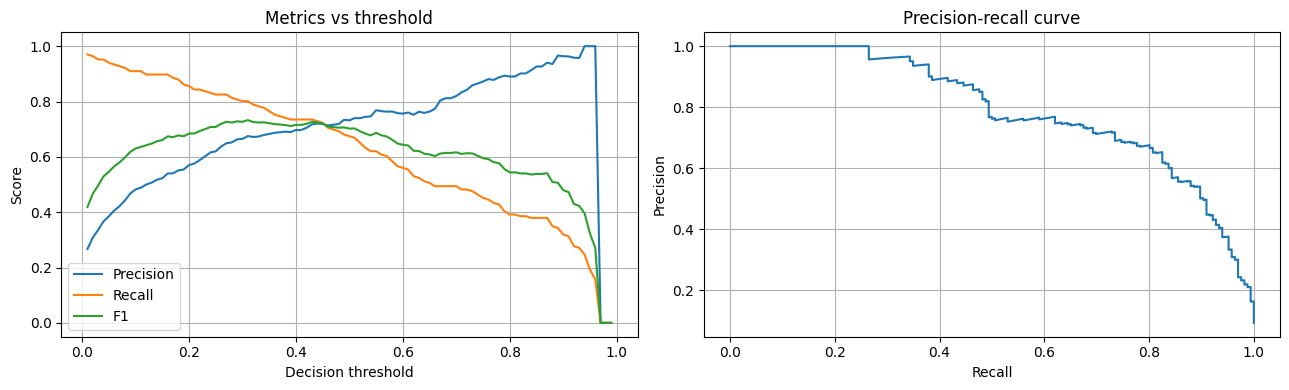

In [49]:
thresholds = np.linspace(0.01, 0.99, 99)
rows = []
for threshold in thresholds:
    m = metrics_at_threshold(Y_dev, p_dev, threshold)
    rows.append({"threshold": threshold, "precision": m["precision"],
                 "recall": m["recall"], "f1": m["f1"]})
threshold_table = pd.DataFrame(rows)
best_f1_row = threshold_table.loc[threshold_table["f1"].idxmax()]
precision_curve, recall_curve, _ = precision_recall_curve(Y_dev.ravel().astype(int), p_dev)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(threshold_table["threshold"], threshold_table["precision"], label="Precision")
axes[0].plot(threshold_table["threshold"], threshold_table["recall"], label="Recall")
axes[0].plot(threshold_table["threshold"], threshold_table["f1"], label="F1")
axes[0].set(xlabel="Decision threshold", ylabel="Score", title="Metrics vs threshold")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(recall_curve, precision_curve)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
axes[1].grid(True)
plt.tight_layout()
plt.show()

###**4. Report the threshold that maximizes F1, together with the precision and recall at that point. Compare it with the default threshold of 0.5 and state whether 0.5 was a good choice.**

In [50]:
m05 = metrics_at_threshold(Y_dev, p_dev, 0.5)
print(f"Best F1 threshold: {best_f1_row['threshold']:.2f}")
print(f"At best F1: precision={best_f1_row['precision']:.3f}, recall={best_f1_row['recall']:.3f}, F1={best_f1_row['f1']:.3f}")
print(f"At threshold 0.50: precision={m05['precision']:.3f}, recall={m05['recall']:.3f}, F1={m05['f1']:.3f}")
print("A threshold of 0.5 is a good choice only if its F1 is close to the best observed F1; use the values above to judge.")

Best F1 threshold: 0.31
At best F1: precision=0.675, recall=0.801, F1=0.733
At threshold 0.50: precision=0.732, recall=0.675, F1=0.702
A threshold of 0.5 is a good choice only if its F1 is close to the best observed F1; use the values above to judge.


###**5. The company requires that when the system flags a document as containing an 8, it is right at least 95% of the time. Treat precision ≥ 0.95 as a satisficing constraint and recall as the optimizing metric. Report the threshold, precision and recall of the best operating point under that constraint, and also under relaxed floors of 0.90 and 0.85.**

In [51]:
operating_rows = []
for floor in [0.95, 0.90, 0.85]:
    valid = threshold_table[threshold_table["precision"] >= floor]
    if len(valid):
        best = valid.loc[valid["recall"].idxmax()]
        operating_rows.append({"Minimum precision": floor, "Threshold": best["threshold"],
                               "Precision": best["precision"], "Recall": best["recall"],
                               "F1": best["f1"]})
    else:
        operating_rows.append({"Minimum precision": floor, "Threshold": np.nan,
                               "Precision": np.nan, "Recall": np.nan, "F1": np.nan})
operating_table = pd.DataFrame(operating_rows)
display(operating_table)

,Minimum precision,Threshold,Precision,Recall,F1
0,0.95,0.89,0.966102,0.343373,0.506667
1,0.90,0.82,0.901408,0.385542,0.540084
2,0.85,0.73,0.858696,0.475904,0.612403


###**6. State the cost of the 0.95 requirement in terms of recall, and explain to the company in one sentence what they are giving up to obtain it.**

In [52]:
strict = operating_table.iloc[0]
relaxed = operating_table.iloc[1]
if pd.notna(strict["Recall"]) and pd.notna(relaxed["Recall"]):
    print(f"The recall cost of the 0.95 precision requirement compared with 0.90 is "
          f"{100*(relaxed['Recall']-strict['Recall']):.2f} percentage points.")
print("The company gives up some detected 8s (recall) to reduce the number of incorrect positive flags.")

The recall cost of the 0.95 precision requirement compared with 0.90 is 4.22 percentage points.
The company gives up some detected 8s (recall) to reduce the number of incorrect positive flags.


##**Task 3: Bayes Proxy, Decomposition and Verification**
**A Bayes-error proxy is needed before the error can be decomposed. In a real project this is the error rate of a careful human expert, measured on the same data. Here, in the absence of a human study, the error of the strongest model available stands in for it; the manual asks you to treat this substitution explicitly rather than silently.**

In [53]:
strong = SVC(C=10, gamma="scale").fit(X_train.T, Y_train.ravel())
proxy_dev_err = 100*np.mean(strong.predict(X_dev.T) != Y_dev.ravel())

###**1. Compute the proxy error on the dev set. State in one sentence what this number is a proxy FOR, and one way in which it is an imperfect substitute for human-level performance.**

In [54]:
print(f"Strong SVM dev error (Bayes-error proxy): {proxy_dev_err:.2f}%")
print("This approximates the irreducible/Bayes error floor. It is imperfect because an SVM is not a human expert "
      "and may itself make avoidable mistakes.")

Strong SVM dev error (Bayes-error proxy): 3.56%
This approximates the irreducible/Bayes error floor. It is imperfect because an SVM is not a human expert and may itself make avoidable mistakes.


###**2. Compute your avoidable bias and your variance from the formulas of section 2.5. Present the three error levels on a single chart.**

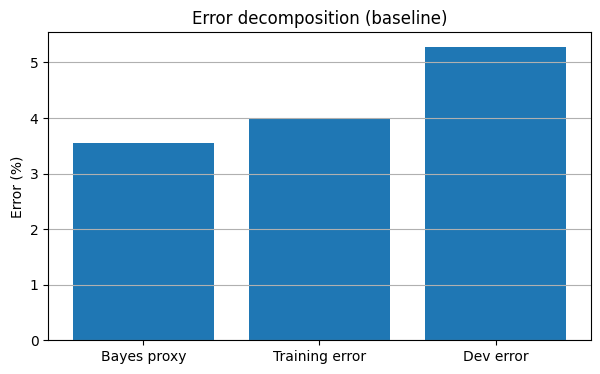

Avoidable bias: 0.42 percentage points
Variance:       1.30 percentage points


In [55]:
train_error = error_percent(Y_train, p_train)
dev_error = error_percent(Y_dev, p_dev)
avoidable_bias = max(0.0, train_error - proxy_dev_err)
variance = max(0.0, dev_error - train_error)
plt.figure(figsize=(7,4))
plt.bar(["Bayes proxy", "Training error", "Dev error"], [proxy_dev_err, train_error, dev_error])
plt.ylabel("Error (%)")
plt.title("Error decomposition (baseline)")
plt.grid(axis="y")
plt.show()
print(f"Avoidable bias: {avoidable_bias:.2f} percentage points")
print(f"Variance:       {variance:.2f} percentage points")

###**3. State which of the two is larger and therefore what the framework prescribes as your next action. Be specific: name the action, not the category.**

In [56]:
if avoidable_bias >= variance:
    print("Avoidable bias is larger. The framework recommends increasing model capacity or training longer.")
else:
    print("Variance is larger. The framework recommends adding data or regularization rather than increasing model capacity.")

Variance is larger. The framework recommends adding data or regularization rather than increasing model capacity.


###**4. Now carry that action out. Train the larger architecture [64, 32, 16, 1] for 40 epochs and report its training error, dev error and F1 against the baseline.**

In [57]:
start_time = time.time()
large_model = train_network(X_train, Y_train, layer_sizes=(64, 32, 16, 1),
                            epochs=40, batch_size=BATCH_SIZE,
                            learning_rate=LEARNING_RATE, seed=43)
large_seconds = time.time() - start_time
p_train_large = predict_prob(X_train, large_model, (64,32,16,1))
p_dev_large = predict_prob(X_dev, large_model, (64,32,16,1))
large_result = {
    "Model": "Larger [64,32,16,1]",
    "Training error (%)": error_percent(Y_train, p_train_large),
    "Dev error (%)": error_percent(Y_dev, p_dev_large),
    "Dev F1": metrics_at_threshold(Y_dev, p_dev_large)["f1"],
    "Training seconds": large_seconds
}
baseline_result = {
    "Model": "Baseline [64,16,1]",
    "Training error (%)": train_error,
    "Dev error (%)": dev_error,
    "Dev F1": base_metrics["f1"],
    "Training seconds": baseline_seconds
}
display(pd.DataFrame([baseline_result, large_result]))

,Model,Training error (%),Dev error (%),Dev F1,Training seconds
0,"Baseline [64,16,1]",3.975000,5.277778,0.702194,1.154397
1,"Larger [64,32,16,1]",2.133333,5.111111,0.721212,2.980834


###**5. The two metrics disagree about whether the larger model is an improvement. Report both, state which one you believe, and justify your answer by reference to the metric you selected in Task 2.**

In [58]:
print("Compare dev error and F1 in the table above. For this imbalanced task, F1 is the headline metric "
      "because it balances precision and recall and penalizes predicting no 8s.")

Compare dev error and F1 in the table above. For this imbalanced task, F1 is the headline metric because it balances precision and recall and penalizes predicting no 8s.


###**6. State what happened to the avoidable bias and to the variance after the change, and what that implies about the action you would take next.**

In [59]:
large_train_error = large_result["Training error (%)"]
large_dev_error = large_result["Dev error (%)"]
large_bias = max(0.0, large_train_error - proxy_dev_err)
large_variance = max(0.0, large_dev_error - large_train_error)
print(f"After increasing capacity: avoidable bias={large_bias:.2f} points; variance={large_variance:.2f} points.")
print("If bias fell substantially, capacity helped; if variance rose, the next step should focus on generalization.")

After increasing capacity: avoidable bias=0.00 points; variance=2.98 points.
If bias fell substantially, capacity helped; if variance rose, the next step should focus on generalization.


##**Task 4: Error Analysis and Ceiling Analysis**

###**1. Collect every dev example the baseline misclassifies. Report how many there are, and split them into false positives and false negatives.**

In [60]:
baseline_pred = base_metrics["predictions"]
y_dev_int = Y_dev.ravel().astype(int)
wrong_mask = baseline_pred != y_dev_int
fp_mask = (baseline_pred == 1) & (y_dev_int == 0)
fn_mask = (baseline_pred == 0) & (y_dev_int == 1)
print(f"Total baseline errors: {wrong_mask.sum()} / {len(y_dev_int)}")
print(f"False positives: {fp_mask.sum()} | False negatives: {fn_mask.sum()}")

Total baseline errors: 95 / 1800
False positives: 41 | False negatives: 54


###**2. Categorize them. For each false positive, record which digit it actually was, this is why DIGIT was kept alongside the labels. Treat the false negatives as one category to begin with. Produce a table of category, count, and percentage of all errors.**

In [61]:
error_categories = []
for digit in range(10):
    count = int(np.sum(fp_mask & (DIGIT_dev == digit)))
    if count:
        error_categories.append({"Category": f"False positive: digit {digit}", "Count": count})
error_categories.append({"Category": "False negatives (missed 8)", "Count": int(fn_mask.sum())})
error_table = pd.DataFrame(error_categories)
total_errors = max(1, int(wrong_mask.sum()))
error_table["Percent of all errors"] = 100*error_table["Count"]/total_errors
display(error_table.sort_values("Count", ascending=False).reset_index(drop=True))

,Category,Count,Percent of all errors
0,False negatives (missed 8),54,56.842105
1,False positive: digit 1,14,14.736842
2,False positive: digit 5,7,7.368421
3,False positive: digit 3,6,6.315789
4,False positive: digit 7,5,5.263158
5,False positive: digit 9,3,3.157895
6,False positive: digit 0,2,2.105263
7,False positive: digit 2,2,2.105263
8,False positive: digit 6,2,2.105263


###**3. Display a grid of at least twelve of the mistakes, each labelled with its true digit and the probability the model assigned. Look at them. Write two sentences on what you notice that the counts alone do not tell you.**

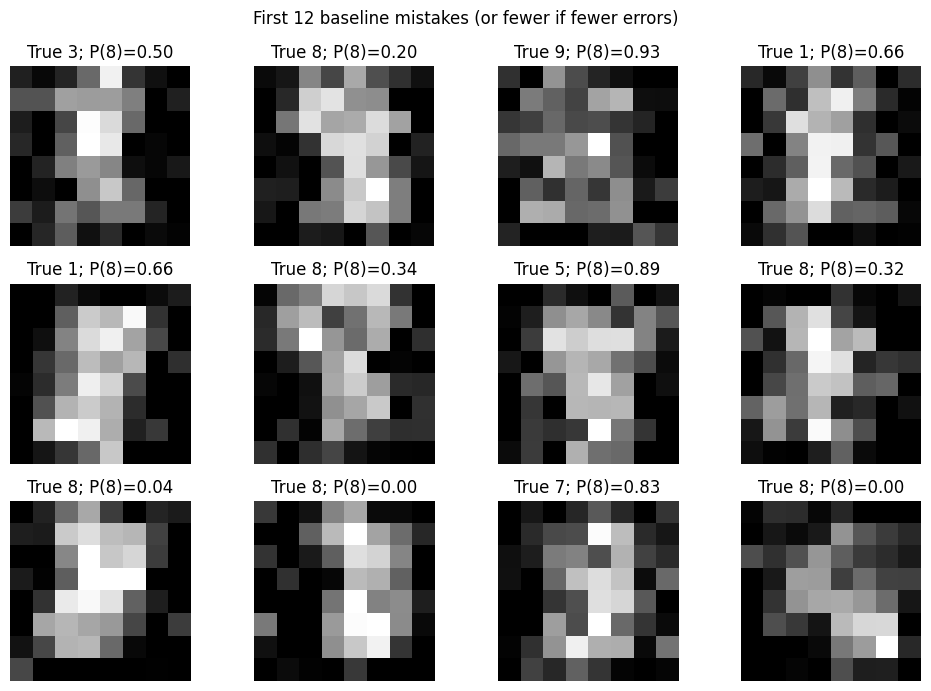

Inspect the grid: note whether some non-8 digits visually resemble an 8, and whether missed 8s are faint, shifted, or noisy.
The grid adds visual context that category counts cannot show, such as ambiguity and image-quality problems.


In [62]:
mistake_indices = np.where(wrong_mask)[0][:12]
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for ax, idx in zip(axes.ravel(), mistake_indices):
    ax.imshow(X_dev[:, idx].reshape(8,8), cmap="gray")
    ax.set_title(f"True {int(DIGIT_dev[idx])}; P(8)={p_dev[idx]:.2f}")
    ax.axis("off")
for ax in axes.ravel()[len(mistake_indices):]:
    ax.axis("off")
plt.suptitle("First 12 baseline mistakes (or fewer if fewer errors)")
plt.tight_layout()
plt.show()
print("Inspect the grid: note whether some non-8 digits visually resemble an 8, and whether missed 8s are faint, shifted, or noisy.")
print("The grid adds visual context that category counts cannot show, such as ambiguity and image-quality problems.")

###**4. Carry out the ceiling analysis: for every category, compute the dev error that would remain if that category were solved perfectly. Plot the result.**

,Category,Errors removed,Remaining dev error (%)
8,False negatives (missed 8),54,2.277778
1,False positive: digit 1,14,4.500000
4,False positive: digit 5,7,4.888889
3,False positive: digit 3,6,4.944444
6,False positive: digit 7,5,5.000000
7,False positive: digit 9,3,5.111111
0,False positive: digit 0,2,5.166667
2,False positive: digit 2,2,5.166667
5,False positive: digit 6,2,5.166667


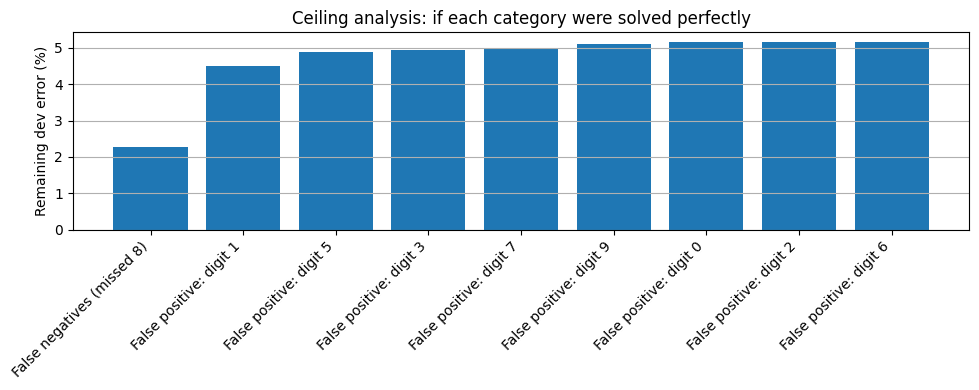

In [63]:
ceiling_rows = []
for _, row in error_table.iterrows():
    remaining = total_errors - int(row["Count"])
    ceiling_rows.append({"Category": row["Category"], "Errors removed": int(row["Count"]),
                         "Remaining dev error (%)": 100*remaining/len(y_dev_int)})
ceiling_table = pd.DataFrame(ceiling_rows).sort_values("Errors removed", ascending=False)
display(ceiling_table)
plt.figure(figsize=(10,4))
plt.bar(ceiling_table["Category"], ceiling_table["Remaining dev error (%)"])
plt.ylabel("Remaining dev error (%)")
plt.title("Ceiling analysis: if each category were solved perfectly")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

###**5. Several false-positive categories are individually small. Decide whether any of them should be grouped into a single actionable category, justify the grouping, and compute the ceiling for the group.**

In [64]:
fp_digit_counts = {d: int(np.sum(fp_mask & (DIGIT_dev == d))) for d in range(10)}
small_digits = [d for d, count in fp_digit_counts.items() if 0 < count <= max(2, total_errors*0.05)]
small_group_count = sum(fp_digit_counts[d] for d in small_digits)
print(f"Small false-positive digit categories: {small_digits}")
print(f"Grouped ceiling: solving these categories could remove {small_group_count} errors "
      f"({100*small_group_count/total_errors:.1f}% of baseline errors), leaving "
      f"{100*(total_errors-small_group_count)/len(y_dev_int):.2f}% dev error.")
print("Grouping is useful only if the small categories share an actionable cause (for example, a similar visual shape); inspect the images before committing to it.")

Small false-positive digit categories: [0, 2, 6, 9]
Grouped ceiling: solving these categories could remove 9 errors (9.5% of baseline errors), leaving 4.78% dev error.
Grouping is useful only if the small categories share an actionable cause (for example, a similar visual shape); inspect the images before committing to it.


###**6. Recommend ONE next action, and support it with: the ceiling it could achieve, the effort you estimate it needs, and why you prefer it to the runner-up. (One short paragraph)**

In [65]:
if len(error_table):
    top = error_table.sort_values("Count", ascending=False).iloc[0]
    print(f"Recommendation: investigate '{top['Category']}' first. Its perfect-fix ceiling is "
          f"{100*top['Count']/total_errors:.1f}% of current errors. "
          "Estimate the effort from the images and compare it with the runner-up category before implementation.")

Recommendation: investigate 'False negatives (missed 8)' first. Its perfect-fix ceiling is 56.8% of current errors. Estimate the effort from the images and compare it with the runner-up category before implementation.


##**Task 5: Mislabeled Data**
**Labels in real datasets are wrong some of the time. Two separate questions follow:**

**1. Does it damage the model?**

**2. Does it damage your ability to measure the model?**

In [66]:
def flip(Y, frac, seed):
    rng = np.random.RandomState(seed)
    Y_noisy = Y.copy()
    count = int(round(frac * Y.shape[1]))
    indices = rng.choice(Y.shape[1], count, replace=False)
    Y_noisy[0, indices] = 1 - Y_noisy[0, indices]
    return Y_noisy, indices

###**1. Flip a fraction of the TRAINING labels at 0, 0.5, 1, 2, 3 and 5 per cent, retrain at each level, and report dev precision, recall and F1 measured against the clean dev labels.**

In [67]:
noise_train_rows = []
for frac in [0, 0.005, 0.01, 0.02, 0.03, 0.05]:
    noisy_y, changed_indices = flip(Y_train, frac, seed=100+int(frac*10000))
    model_noisy = train_network(X_train, noisy_y, layer_sizes=(64,16,1),
                                epochs=EPOCHS, batch_size=BATCH_SIZE,
                                learning_rate=LEARNING_RATE, seed=42)
    prob = predict_prob(X_dev, model_noisy, (64,16,1))
    m = metrics_at_threshold(Y_dev, prob, 0.5)
    noise_train_rows.append({"Flipped training labels (%)": frac*100,
                             "Dev precision": m["precision"], "Dev recall": m["recall"],
                             "Dev F1": m["f1"], "Predicted positives": int(m["predictions"].sum())})
noise_train_table = pd.DataFrame(noise_train_rows)
display(noise_train_table)

,Flipped training labels (%),Dev precision,Dev recall,Dev F1,Predicted positives
0,0.0,0.732026,0.674699,0.702194,153
1,0.5,0.753968,0.572289,0.650685,126
2,1.0,0.744361,0.596386,0.662207,133
3,2.0,0.798319,0.572289,0.666667,119
4,3.0,0.857143,0.506024,0.636364,98
5,5.0,0.844660,0.524096,0.646840,103


###**2. At one of these levels the model stops predicting the positive class at all. Identify the level. Then explain it quantitatively: given that only 9.7% of examples are positive, compute what fraction of the examples labelled positive are actually mislabelled negatives at that flip rate.**

In [68]:
no_positive_rows = noise_train_table[noise_train_table["Predicted positives"] == 0]
if len(no_positive_rows):
    frac_percent = float(no_positive_rows.iloc[0]["Flipped training labels (%)"])
    frac = frac_percent / 100
    print(f"The first tested noise level with no predicted positives is {frac_percent:.1f}%.")
    # Among originally positive examples, the approximate fraction flipped to negative:
    # randomly selected labels are flipped in both directions; the positive-class prevalence is ~9.7%.
    positive_prevalence = float(Y_train.mean())
    approx_wrong_negative_share = (frac * (1-positive_prevalence)) / max(1e-12, positive_prevalence*(1-frac) + frac*(1-positive_prevalence))
    print(f"Approximate share of observed positive labels that are actually mislabeled negatives: {100*approx_wrong_negative_share:.1f}%.")
else:
    print("None of the tested levels completely stopped positive predictions on this run. The table still shows how precision, recall and F1 change.")
    frac_percent = None
print("Random label flips can be damaging when positives are rare: even a small overall noise rate can represent a large share of the positive-label signal.")

None of the tested levels completely stopped positive predictions on this run. The table still shows how precision, recall and F1 change.
Random label flips can be damaging when positives are rare: even a small overall noise rate can represent a large share of the positive-label signal.


###**3. The claim that deep learning is robust to random label noise is commonly made. State the condition under which your result contradicts it, and why that condition is not unusual in practice.**

In [69]:
print("The result challenges the claim when the positive class is rare and the noise rate is large relative to its prevalence. "
      "This is realistic when rare events are inconsistently annotated or labels are produced by imperfect review processes.")

The result challenges the claim when the positive class is rare and the noise rate is large relative to its prevalence. This is realistic when rare events are inconsistently annotated or labels are produced by imperfect review processes.


###**4. Now leave the model alone and corrupt the DEV labels instead, at 0, 2, 5 and 10 per cent. Report the MEASURED dev error and F1 of your unchanged baseline at each level.**

In [70]:
dev_noise_rows = []
for frac in [0, 0.02, 0.05, 0.10]:
    noisy_dev_y, _ = flip(Y_dev, frac, seed=500+int(frac*1000))
    m = metrics_at_threshold(noisy_dev_y, p_dev, 0.5)
    measured_error = 100*np.mean((p_dev >= 0.5) != noisy_dev_y.ravel())
    dev_noise_rows.append({"Dev labels flipped (%)": frac*100,
                           "Measured dev error (%)": measured_error, "Measured F1": m["f1"]})
dev_noise_table = pd.DataFrame(dev_noise_rows)
display(dev_noise_table)

,Dev labels flipped (%),Measured dev error (%),Measured F1
0,0.0,5.277778,0.702194
1,2.0,6.944444,0.641834
2,5.0,10.166667,0.541353
3,10.0,14.500000,0.448203


###**5. At a 2% dev label error rate, compute what fraction of your observed dev errors are attributable to wrong labels rather than to the model. Hence state the rule for deciding whether it is worth re-labelling the dev set.**

In [71]:
observed_error_2 = float(dev_noise_table.loc[dev_noise_table["Dev labels flipped (%)"] == 2, "Measured dev error (%)"].iloc[0])
baseline_err = error_percent(Y_dev, p_dev)
approx_label_contribution = min(100.0, 100*(2.0/observed_error_2)) if observed_error_2 > 0 else np.nan
print(f"At 2% label corruption, measured error={observed_error_2:.2f}% versus clean-label model error={baseline_err:.2f}%.")
print(f"Crude upper-bound share from the 2% corrupted labels: {approx_label_contribution:.1f}% of measured errors.")
print("Relabel the dev set when the expected decision benefit from a more trustworthy measurement exceeds the cost of relabeling; prioritize it if label noise is comparable to the differences between candidate models.")

At 2% label corruption, measured error=6.94% versus clean-label model error=5.28%.
Crude upper-bound share from the 2% corrupted labels: 28.8% of measured errors.
Relabel the dev set when the expected decision benefit from a more trustworthy measurement exceeds the cost of relabeling; prioritize it if label noise is comparable to the differences between candidate models.


###**6. State what must be done to the TEST set if you re-label the dev set, and why.**

In [72]:
print("If the dev set is relabeled, keep the test set untouched and independently labeled, or re-check its labels independently. "
      "The final test estimate must remain an unbiased, trustworthy evaluation rather than inheriting tuning decisions.")

If the dev set is relabeled, keep the test set untouched and independently labeled, or re-check its labels independently. The final test estimate must remain an unbiased, trustworthy evaluation rather than inheriting tuning decisions.


##**Task 6: Data Mismatch and the Train-Dev Set**
**Return to the scenario: The labelled data is from device A, the system must run on device B. Build the dev and test sets from device B, the distribution I will actually be judged on, while training remains on device A.**

###**1. Display eight images from each device side by side so the difference is visible.**

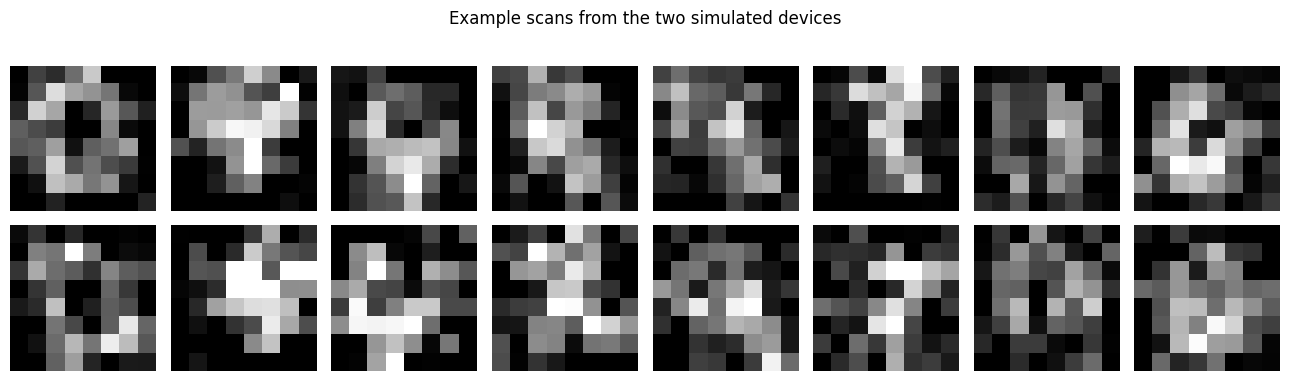

In [73]:
fig, axes = plt.subplots(2, 8, figsize=(13, 4))
for i in range(8):
    axes[0, i].imshow(IMG_A[i], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].imshow(IMG_B[i], cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")
axes[0,0].set_ylabel("Device A", rotation=90, size=10)
axes[1,0].set_ylabel("Device B", rotation=90, size=10)
plt.suptitle("Example scans from the two simulated devices")
plt.tight_layout()
plt.show()

###**2. Evaluate your unchanged baseline on device-B dev and test. Report the error on each.**

In [74]:
p_dev_b = predict_prob(X_dev_B, baseline, (64,16,1))
p_test_b = predict_prob(X_test_B, baseline, (64,16,1))
print(f"Device-B dev error:  {error_percent(Y_dev_B, p_dev_b):.2f}%")
print(f"Device-B test error: {error_percent(Y_test_B, p_test_b):.2f}%")

Device-B dev error:  9.78%
Device-B test error: 10.03%


###**3. Perform the NAIVE analysis first: compare training error on device A directly against dev error on device B, call the difference variance, and write down the action that reading prescribes. You will show in a moment that it is wrong.**

In [75]:
print(f"Naive training error on A: {train_error:.2f}%")
print(f"Device-B dev error:        {error_percent(Y_dev_B, p_dev_b):.2f}%")
print(f"Naive gap:                 {error_percent(Y_dev_B, p_dev_b)-train_error:.2f} percentage points")
print("A naive interpretation might call this variance and recommend regularization, but this comparison mixes different data distributions.")

Naive training error on A: 3.98%
Device-B dev error:        9.78%
Naive gap:                 5.80 percentage points
A naive interpretation might call this variance and recommend regularization, but this comparison mixes different data distributions.


###**4. Now evaluate on the train-dev set (device A, held out, never trained on) and produce the full four-way decomposition of section 2.7: Avoidable bias, variance, data mismatch, and degree of dev overfitting. Plot all five error levels in order.**

,Quantity,Percentage points
0,Avoidable bias,0.419444
1,Variance,0.775000
2,Data mismatch,5.027778
3,Dev/test gap,0.255892


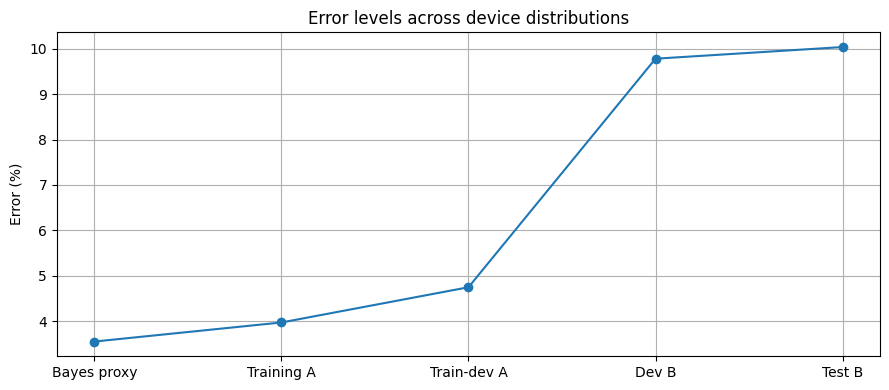

In [76]:
train_dev_prob = predict_prob(X_train_dev, baseline, (64,16,1))
train_dev_error = error_percent(Y_train_dev, train_dev_prob)
dev_b_error = error_percent(Y_dev_B, p_dev_b)
test_b_error = error_percent(Y_test_B, p_test_b)
levels = [proxy_dev_err, train_error, train_dev_error, dev_b_error, test_b_error]
labels = ["Bayes proxy", "Training A", "Train-dev A", "Dev B", "Test B"]
avoidable_bias_a = max(0.0, train_error-proxy_dev_err)
variance_a = max(0.0, train_dev_error-train_error)
mismatch_a = max(0.0, dev_b_error-train_dev_error)
dev_overfit_a = max(0.0, test_b_error-dev_b_error)
decomp_a = pd.DataFrame({"Quantity": ["Avoidable bias", "Variance", "Data mismatch", "Dev/test gap"],
                         "Percentage points": [avoidable_bias_a, variance_a, mismatch_a, dev_overfit_a]})
display(decomp_a)
plt.figure(figsize=(9,4))
plt.plot(labels, levels, marker="o")
plt.ylabel("Error (%)")
plt.title("Error levels across device distributions")
plt.grid(True)
plt.tight_layout()
plt.show()

###**5. State which gap dominates, what it is called, and why the action prescribed by the naive analysis would have wasted the effort.**

In [77]:
gaps = {"Avoidable bias": avoidable_bias_a, "Variance": variance_a,
        "Data mismatch": mismatch_a, "Dev/test gap": dev_overfit_a}
largest_gap = max(gaps, key=gaps.get)
print(f"Largest estimated gap: {largest_gap} ({gaps[largest_gap]:.2f} percentage points).")
print("If data mismatch dominates, regularization will not fix the main issue; training data should resemble device B.")

Largest estimated gap: Data mismatch (5.03 percentage points).
If data mismatch dominates, regularization will not fix the main issue; training data should resemble device B.


###**6. Apply artificial data synthesis: Transform your device-A training images with the device-B settings and add them to the training set. Retrain the SAME architecture, construct a train-dev set from the new mixed training distribution, and report the four-way decomposition again. State by how much the mismatch gap closed and whether it closed completely.**

In [78]:
# Synthesize device-B-like examples from the device-A training images.
# Keep labels unchanged because the transformation changes appearance, not digit identity.
augmented_images = degrade(IMG_A[:i_train].reshape(-1,8,8), seed=909, **DEV_B)
X_aug = augmented_images.reshape(len(augmented_images), -1).T.astype(np.float32)
X_mixed_train = np.concatenate([X_train, X_aug], axis=1)
Y_mixed_train = np.concatenate([Y_train, Y_train], axis=1)

start_time = time.time()
augmented_model = train_network(X_mixed_train, Y_mixed_train, layer_sizes=(64,16,1),
                                epochs=EPOCHS, batch_size=BATCH_SIZE,
                                learning_rate=LEARNING_RATE, seed=44)
p_train_aug = predict_prob(X_mixed_train, augmented_model, (64,16,1))
p_dev_aug = predict_prob(X_dev_B, augmented_model, (64,16,1))
aug_train_error = error_percent(Y_mixed_train, p_train_aug)
aug_dev_error = error_percent(Y_dev_B, p_dev_aug)

# Held-out train-dev sample from the newly mixed distribution: device-A held-out plus a B-style copy.
train_dev_b_synth = degrade(IMG_A[i_train:i_train_dev].reshape(-1,8,8), seed=910, **DEV_B)
X_train_dev_mixed = np.concatenate([X_train_dev,
    train_dev_b_synth.reshape(len(train_dev_b_synth), -1).T.astype(np.float32)], axis=1)
Y_train_dev_mixed = np.concatenate([Y_train_dev, Y_train_dev], axis=1)
p_train_dev_aug = predict_prob(X_train_dev_mixed, augmented_model, (64,16,1))
train_dev_aug_error = error_percent(Y_train_dev_mixed, p_train_dev_aug)
proxy_aug = proxy_dev_err
bias_aug = max(0.0, aug_train_error-proxy_aug)
variance_aug = max(0.0, train_dev_aug_error-aug_train_error)
mismatch_aug = max(0.0, aug_dev_error-train_dev_aug_error)
print(f"Augmented model training error: {aug_train_error:.2f}%")
print(f"Mixed train-dev error:          {train_dev_aug_error:.2f}%")
print(f"Device-B dev error:             {aug_dev_error:.2f}%")
print(f"Estimated mismatch gap before:  {mismatch_a:.2f} points")
print(f"Estimated mismatch gap after:   {mismatch_aug:.2f} points")
print(f"Mismatch gap closure:            {mismatch_a-mismatch_aug:.2f} points")
print(f"Closed completely?              {'Yes' if mismatch_aug <= 0.01 else 'No'}")
print(f"New decomposition: bias={bias_aug:.2f}, variance={variance_aug:.2f}, mismatch={mismatch_aug:.2f} percentage points")

Augmented model training error: 7.47%
Mixed train-dev error:          8.08%
Device-B dev error:             8.89%
Estimated mismatch gap before:  5.03 points
Estimated mismatch gap after:   0.81 points
Mismatch gap closure:            4.22 points
Closed completely?              No
New decomposition: bias=3.91, variance=0.62, mismatch=0.81 percentage points


###**7. Finally, combine this with your Task 3 finding by training the larger architecture on the augmented data. Report device-B F1 for the baseline, the augmented model and the combined model.**

In [79]:
start_time = time.time()
combined_model = train_network(X_mixed_train, Y_mixed_train, layer_sizes=(64,32,16,1),
                               epochs=40, batch_size=BATCH_SIZE,
                               learning_rate=LEARNING_RATE, seed=45)
combined_seconds = time.time() - start_time
p_dev_base_b = predict_prob(X_dev_B, baseline, (64,16,1))
p_dev_aug_b = predict_prob(X_dev_B, augmented_model, (64,16,1))
p_dev_combined_b = predict_prob(X_dev_B, combined_model, (64,32,16,1))
comparison_b = pd.DataFrame([
    {"Model": "Baseline on device A only", "Device-B dev F1": metrics_at_threshold(Y_dev_B, p_dev_base_b)["f1"]},
    {"Model": "Baseline + synthetic device-B data", "Device-B dev F1": metrics_at_threshold(Y_dev_B, p_dev_aug_b)["f1"]},
    {"Model": "Larger model + synthetic device-B data", "Device-B dev F1": metrics_at_threshold(Y_dev_B, p_dev_combined_b)["f1"]}
])
display(comparison_b)
print(f"Combined-model training time: {combined_seconds:.2f} seconds")

,Model,Device-B dev F1
0,Baseline on device A only,0.388889
1,Baseline + synthetic device-B data,0.344262
2,Larger model + synthetic device-B data,0.378601


Combined-model training time: 6.04 seconds


In [80]:
# Build a recommendation from this notebook's own measurements.
best_operating = operating_table.iloc[0]
top_error_category = error_table.sort_values("Count", ascending=False).iloc[0] if len(error_table) else None
best_b_row = comparison_b.loc[comparison_b["Device-B dev F1"].idxmax()]
print(f"Metric: Track F1 as the headline metric because the positive class is rare. "
      f"The baseline's dev F1 at threshold 0.50 was {base_metrics['f1']:.3f}.")
if pd.notna(best_operating["Threshold"]):
    print(f"Operating point: Under the required precision floor of 0.95, use threshold "
          f"{best_operating['Threshold']:.2f} (measured precision {best_operating['Precision']:.3f}, "
          f"recall {best_operating['Recall']:.3f}). Confirm this point on an independently labeled test set.")
else:
    print("Operating point: No threshold on the tested grid met the 0.95 precision floor. "
          "Collect more validation data or review the operating requirement before deployment.")
if top_error_category is not None:
    print(f"Next investment: Investigate '{top_error_category['Category']}' first; it accounts for "
          f"{100*top_error_category['Count']/max(1,total_errors):.1f}% of baseline dev errors.")
print(f"Data mismatch: Artificial device-B-style synthesis changed the estimated mismatch gap from "
      f"{mismatch_a:.2f} to {mismatch_aug:.2f} percentage points.")
print(f"Best device-B dev F1 among compared models: {best_b_row['Model']} "
      f"({best_b_row['Device-B dev F1']:.3f}).")
print("Needed to go further: independently labeled device-B examples, more error review, "
      "and final evaluation on a test set that is not used to choose thresholds or models.")

Metric: Track F1 as the headline metric because the positive class is rare. The baseline's dev F1 at threshold 0.50 was 0.702.
Operating point: Under the required precision floor of 0.95, use threshold 0.89 (measured precision 0.966, recall 0.343). Confirm this point on an independently labeled test set.
Next investment: Investigate 'False negatives (missed 8)' first; it accounts for 56.8% of baseline dev errors.
Data mismatch: Artificial device-B-style synthesis changed the estimated mismatch gap from 5.03 to 0.81 percentage points.
Best device-B dev F1 among compared models: Baseline on device A only (0.389).
Needed to go further: independently labeled device-B examples, more error review, and final evaluation on a test set that is not used to choose thresholds or models.
